In [27]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core

from hnn_core import MPIBackend

from optim_utils import set_params
from hnn_core.dipole import _rmse
from hnn_core.params import _short_name

from hnn_core import new_calcium_model, simulate_dipole, jones_2009_model
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'


### Feedforward

In [28]:
# Feedforward model parameters

scale_factor = 30000

net = new_calcium_model()
tstop = 1000

location = 'proximal'
burst_std = 20               # Jones 2009: input bursts variance = 400

weights_ampa_p = {'L2_basket': 6e-7, 'L5_pyramidal': 1.2e-7, 'L5_basket': 6e-7}     # max values taken from Jones 2009 for high mu
syn_delays_p = {'L2_basket': 4., 'L5_pyramidal': 5., 'L5_basket': 4}#{'L2_basket': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1}                    # following https://modeldb.science/136803?tab=2&file=JonesEtAl2009/wiring_proc_2Dv2.hoc {'L2_basket': 4., 'L5_pyramidal': 5., 'L5_basket': 4} but this leads to no response at all

net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=284)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor='calcium')[0]

trial_idx = 0  # single trial simulated, choose the first index
# to emulate a larger patch of cortex, we can apply a simple scaling factor
dpl.scale(scale_factor)


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

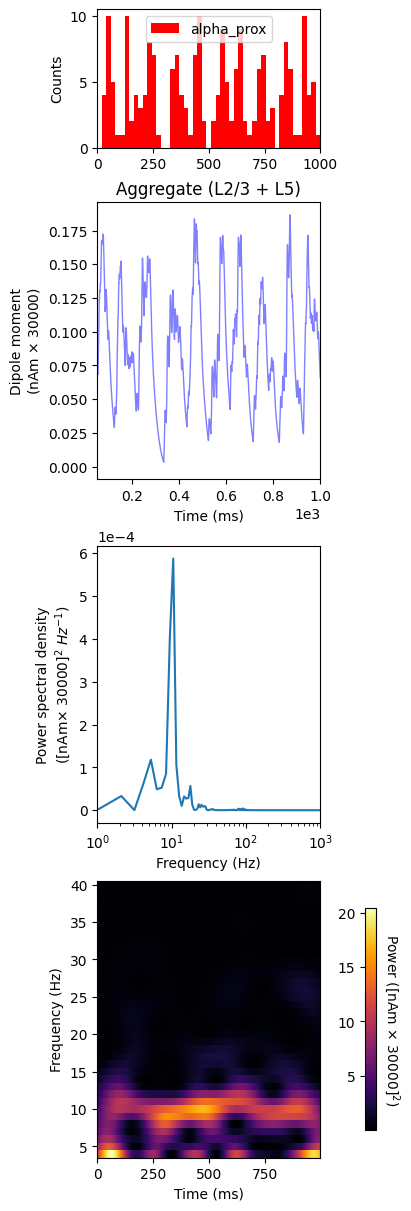

<Figure size 640x480 with 0 Axes>

In [29]:
import matplotlib.pyplot as plt
from hnn_core.viz import plot_dipole, plot_psd, plot_tfr_morlet
import numpy as np

fig, axes = plt.subplots(4, 1, constrained_layout=True, figsize=(4, 12), height_ratios=[0.5, 1, 1, 1])
tmin, tmax = 50, 1000  # exclude the initial burn-in period from the plots

# We'll make a copy of the dipole before smoothing in order to compare
#window_len = 1  # convolve with a 10 ms-long Hamming window
#dpl_smooth = dpl.copy().smooth(window_len)

net.cell_response.plot_spikes_hist(ax=axes[0], show=False)
# Overlay the traces for comparison. The function plot_dipole can plot a list
# of dipoles at once
dpl.plot(tmin=tmin, tmax=tmax, color='b', ax=axes[1], show=False)
#dpl_smooth.plot(tmin=tmin, tmax=tmax, color='r', ax=axes[1], show=False)
axes[1].set_xlim((tmin, tmax))

plot_psd(dpl, fmin=1., fmax=1e3, tmin=tmin, ax=axes[2], show=False)
axes[2].set_xscale('log')

freqs = np.arange(4, 41, 1)
plot_tfr_morlet(dpl, freqs, n_cycles=freqs/1000 * 500, tmin=0, tmax=tmax, layer='agg', padding='zeros', ax=axes[3],
                    colormap='inferno', colorbar=True, colorbar_inside=False, show=True)


plt.tight_layout()

fig.savefig(os.path.join(pathfig, 'alpha.png'))
fig.savefig(os.path.join(pathfig, 'alpha.pdf'))

### Feedback

In [30]:
location = 'distal'
burst_std = 20              # I believe the std was the same for FB and FF inputs in Jones 2009
weights_ampa_d = {'L2_basket': 6e-7*4, 'L5_pyramidal': 1.2e-7*4}
syn_delays_d = {'L2_basket': 4, 'L5_pyramidal': 5.}

delay = 5                   # Jones might have used 3 ms but this works
net.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=296)


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

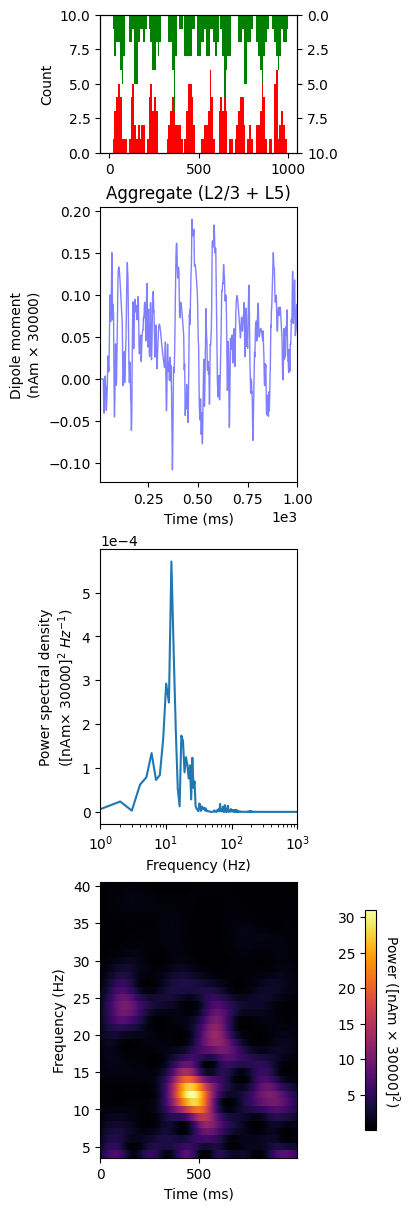

<Figure size 640x480 with 0 Axes>

In [31]:
import numpy as np


with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor='calcium')[0]
dpl.scale(scale_factor)
fig, axes = plt.subplots(4, 1, constrained_layout=True, figsize=(4, 12), height_ratios=[0.5, 1, 1, 1])
tmin, tmax = 10, 1000  # exclude the initial burn-in period from the plots

bins = np.arange(0, 1010, 10)  # histogram bins
# We'll make a copy of the dipole before smoothing in order to compare
# window_len = 10  # convolve with a 10 ms-long Hamming window
# dpl_smooth = dpl.copy().smooth(window_len)

# proximal and distal histogram
spike_prox = np.array(net.cell_response.spike_times_by_type['alpha_prox']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['alpha_dist']).reshape(-1,1)

axes[0].hist(spike_prox, bins, color='r')
axes[0].set_ylim([0, 10])
axes[0].set_ylabel('Count')
ax1tw = axes[0].twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 10])
ax1tw.invert_yaxis()

# Overlay the traces for comparison. The function plot_dipole can plot a list
# of dipoles at once
dpl.plot(tmin=tmin, tmax=tmax, color='b', ax=axes[1], show=False)
# dpl_smooth.plot(tmin=tmin, tmax=tmax, color='r', ax=axes[1], show=False)
axes[1].set_xlim((tmin, tmax))

plot_psd(dpl, fmin=1., fmax=1e3, tmin=tmin, ax=axes[2], show=False)
axes[2].set_xscale('log')

plot_tfr_morlet(dpl, freqs, n_cycles=freqs/1000 * 500, tmin=0, tmax=tmax, layer='agg', padding='zeros', ax=axes[3],
                    colormap='inferno', colorbar=True, colorbar_inside=False, show=True)

plt.tight_layout()

fig.savefig(os.path.join(pathfig, 'alpha_beta_complex.png'))
fig.savefig(os.path.join(pathfig, 'alpha_beta_complex.pdf'))

## Symmetry index

In [32]:
dt = np.diff(dpl.times)[0]
fs = 1000/dt

In [33]:
# symmetry index

from scipy.signal import butter, lfilter, find_peaks

def butter_bandpass(lowcut, highcut, fs, order=5):
        nyq = 0.5 * fs
        low = lowcut / nyq
        high = highcut / nyq
        b, a = butter(order, [low, high], btype='band')
        return b, a


def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = lfilter(b, a, data)
    return y

def symmetry_index(dpl, lowcut=7, highcut=29, show_plot=False):

    cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
        
    filt_dpl = butter_bandpass_filter(dpl.data['agg'], lowcut, highcut, fs, order=2)
    peaks, _ = find_peaks(filt_dpl, prominence=0.01)
    troughs, _ = find_peaks(-filt_dpl, prominence=0.01)

    if len(peaks) == len(troughs):
        if troughs[0] < peaks[0]:
            sind = (np.abs(filt_dpl[peaks[:-1]]) - np.abs(filt_dpl[troughs[1:]]))/(np.abs(filt_dpl[peaks[:-1]]) + np.abs(filt_dpl[troughs[1:]]))
        else:
            sind = (np.abs(filt_dpl[peaks]) - np.abs(filt_dpl[troughs]))/(np.abs(filt_dpl[peaks]) + np.abs(filt_dpl[troughs]))
    elif len(peaks) > len(troughs):
         sind = (np.abs(filt_dpl[peaks[int(len(peaks)-len(troughs)):]]) - np.abs(filt_dpl[troughs]))/(np.abs(filt_dpl[peaks[int(len(peaks)-len(troughs)):]]) + np.abs(filt_dpl[troughs]))
    elif len(peaks) < len(troughs):

        peak_diff = int(len(troughs)-len(peaks))
        if troughs[0] < peaks[0]:
            sind = (np.abs(filt_dpl[peaks]) - np.abs(filt_dpl[troughs[peak_diff:]]))/(np.abs(filt_dpl[peaks]) + np.abs(filt_dpl[troughs[peak_diff:]]))
        else:
            sind = (np.abs(filt_dpl[peaks]) - np.abs(filt_dpl[troughs[:-peak_diff]]))/(np.abs(filt_dpl[peaks]) + np.abs(filt_dpl[troughs[:-peak_diff]]))
         

    if show_plot:

        fig, ax = plt.subplots(1, 1, figsize=(7, 5))
        ax.plot(dpl.times, dpl.data['agg'], label='raw', color=cols[0])
        ax.plot(dpl.times, filt_dpl, label='filtered', color=cols[1])
        ax.plot(dpl.times[peaks], filt_dpl[peaks], 'x', label='peaks', color=cols[2])
        ax.plot(dpl.times[troughs], filt_dpl[troughs], 'x', label='troughs', color=cols[3])
        ax.set_xlabel('time (ms)')
        ax.set_ylabel('dipole (nAm)')
        ax.legend()

        fig.savefig(os.path.join(pathfig, 'symmetry_index.png'))
        fig.savefig(os.path.join(pathfig, 'symmetry_index.pdf'))

    return sind


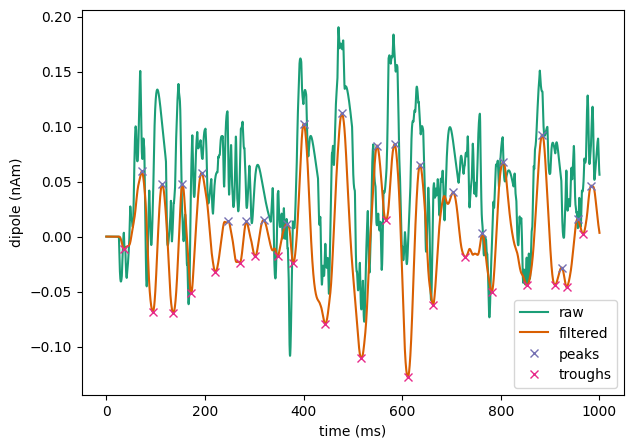

In [34]:
sind = symmetry_index(dpl, lowcut=7, highcut=29, show_plot=True)


In [35]:
# symmetry index for over 30 trials
from hnn_core import JoblibBackend

net = new_calcium_model()
tstop = 1000

location = 'proximal'
burst_std = 20               # Jones 2009: input bursts variance = 400

net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p)

net.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d)

with JoblibBackend(n_jobs=10):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=30, bsl_cor='calcium')



Joblib will run 30 trial(s) in parallel by distributing trials over 10 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Document

In [36]:
sind = np.array(())

for i,trl in enumerate(dpl):
    trl.scale(scale_factor)
    sind = np.append(sind, symmetry_index(trl, lowcut=7, highcut=29, show_plot=False))

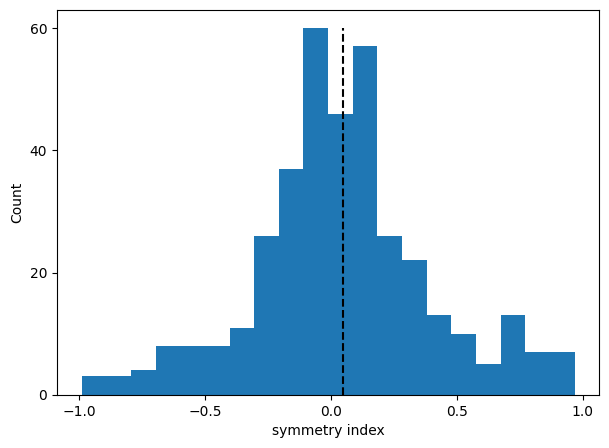

In [39]:
fig, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.hist(sind, bins=20)
ax.set_xlabel('symmetry index')
ax.set_ylabel('Count')
ax.plot(np.ones(50,)*np.median(sind), np.linspace(0,60), 'k', label='mean', linestyle='--')  
ax.set_xticks(np.arange(-1, 1.1, 0.5))
ax.set_yticks(np.arange(0, 61, 20))
fig.savefig(os.path.join(pathfig, 'symmetry_index_30_trials.png'))
fig.savefig(os.path.join(pathfig, 'symmetry_index_30_trials.pdf'))